In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [10]:
dgs1 = pd.read_csv("https://fred.stlouisfed.org/graph/fredgraph.csv?id=DGS1", index_col=0, parse_dates=True, na_values=".")
dgs2 = pd.read_csv("https://fred.stlouisfed.org/graph/fredgraph.csv?id=DGS2", index_col=0, parse_dates=True, na_values=".")
dgs7 = pd.read_csv("https://fred.stlouisfed.org/graph/fredgraph.csv?id=DGS7", index_col=0, parse_dates=True, na_values=".")
dgs10 = pd.read_csv("https://fred.stlouisfed.org/graph/fredgraph.csv?id=DGS10", index_col=0, parse_dates=True, na_values=".")
dff = pd.read_csv("https://fred.stlouisfed.org/graph/fredgraph.csv?id=DFF", index_col=0, parse_dates=True, na_values=".")

In [11]:
yields = pd.concat([dgs1, dgs2, dgs7, dgs10, dff], axis=1).loc["2000-01-01":"2026-09-30"].dropna()
yields_m = yields.resample("ME").last()
yields_m["spread_bp"] = (yields_m["DGS10"] - yields_m["DGS2"]) * 100
yields_m.head()

C:\Users\guney\AppData\Local\Temp\ipykernel_20152\4067582248.py:1: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  yields = pd.concat([dgs1, dgs2, dgs7, dgs10, dff], axis=1).loc["2000-01-01":"2026-09-30"].dropna()


,DGS1,DGS2,DGS7,DGS10,DFF,spread_bp
observation_date,,,,,,
2000-01-31,6.30,6.61,6.75,6.68,5.87,7.0
2000-02-29,6.20,6.53,6.67,6.42,5.85,-11.0
2000-03-31,6.28,6.50,6.28,6.03,6.17,-47.0
2000-04-30,6.24,6.68,6.49,6.23,6.06,-45.0
2000-05-31,6.37,6.69,6.52,6.29,6.83,-40.0


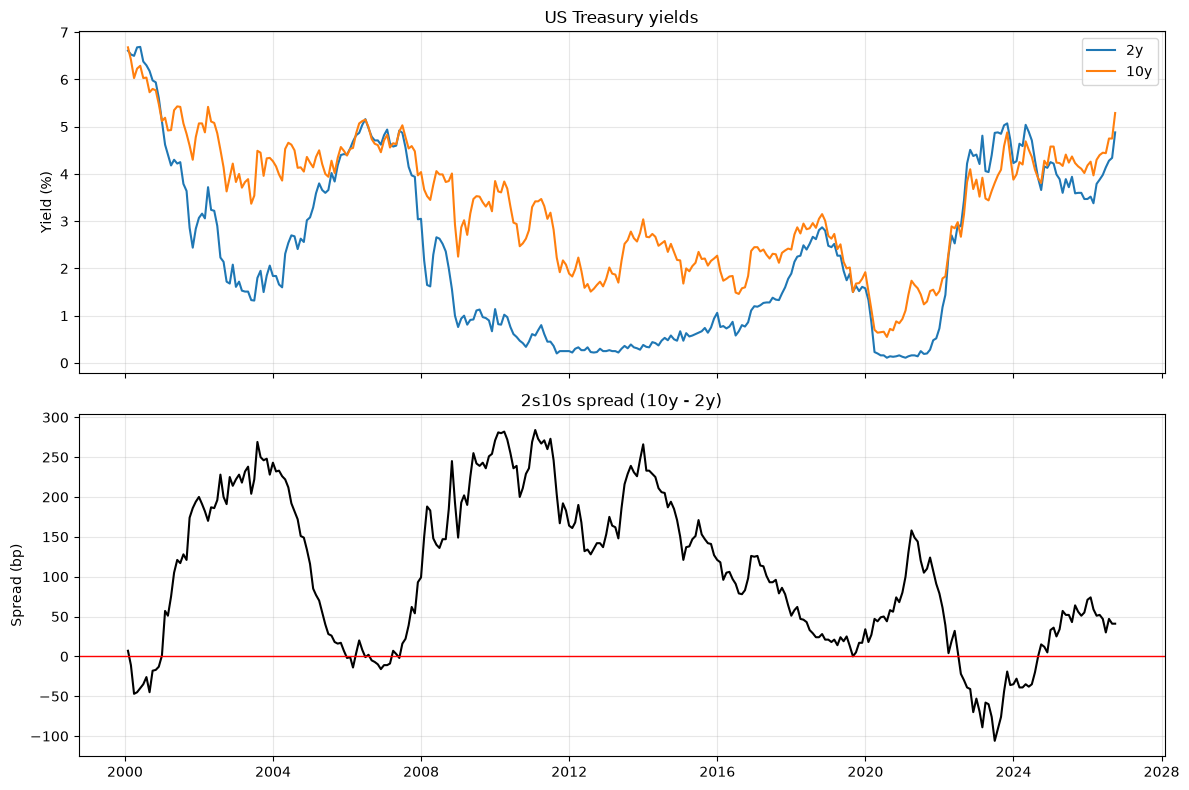

In [12]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

ax1.plot(yields_m.index, yields_m["DGS2"], label="2y")
ax1.plot(yields_m.index, yields_m["DGS10"], label="10y")
ax1.set_ylabel("Yield (%)")
ax1.set_title("US Treasury yields")
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(yields_m.index, yields_m["spread_bp"], color="black")
ax2.axhline(0, color="red", linewidth=1)
ax2.set_ylabel("Spread (bp)")
ax2.set_title("2s10s spread (10y - 2y)")
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [13]:
DV01 = 10_000
yields_m["spread_pnl"] = DV01 * yields_m["spread_bp"].diff()
yields_m["roll"] = (DV01 * ((yields_m["DGS2"] - yields_m["DGS1"]) - (yields_m["DGS10"] - yields_m["DGS7"]) / 3) * 100 / 12).shift(1)

In [14]:
y2 = yields_m["DGS2"] / 100
y10 = yields_m["DGS10"] / 100
r = yields_m["DFF"] / 100

yields_m["notional_2"] = DV01 / ((1 / y2) * (1 - 1 / (1 + y2 / 2) ** 4) * 1e-4)
yields_m["notional_10"] = DV01 / ((1 / y10) * (1 - 1 / (1 + y10 / 2) ** 20) * 1e-4)

yields_m["carry"] = ((yields_m["notional_2"] * (y2 - r) - yields_m["notional_10"] * (y10 - r)) / 12).shift(1)

In [15]:
CAPITAL = 5_000_000

yields_m["carry_roll"] = yields_m["carry"] + yields_m["roll"]
yields_m["total_pnl"] = yields_m["spread_pnl"] + yields_m["carry_roll"]

pnl = yields_m.dropna(subset=["total_pnl"])
f"{len(pnl)} months, {pnl.index[0]:%Y-%m} to {pnl.index[-1]:%Y-%m}"

'320 months, 2000-02 to 2026-09'

In [16]:
def performance(series, base):
    r = series / base
    equity = base + series.cumsum()
    return pd.Series({
        "ann. return": r.mean() * 12,
        "ann. volatility": r.std() * np.sqrt(12),
        "Sharpe": r.mean() / r.std() * np.sqrt(12),
        "max drawdown": (equity / equity.cummax() - 1).min(),
    })


performance(pnl["total_pnl"], CAPITAL)

ann. return        0.009949
ann. volatility    0.116992
Sharpe             0.085041
max drawdown      -0.329635
dtype: float64

In [17]:
COMPONENTS = {"spread": "spread_pnl", "carry + roll": "carry_roll",
              "roll": "roll", "carry": "carry", "total": "total_pnl"}

split = pd.DataFrame(
    {"cumulative $m": [pnl[c].sum() / 1e6 for c in COMPONENTS.values()],
     "ann. % of capital": [pnl[c].mean() * 12 / CAPITAL for c in COMPONENTS.values()],
     "monthly sd $k": [pnl[c].std() / 1e3 for c in COMPONENTS.values()]},
    index=list(COMPONENTS),
)
split.round(3)

,cumulative $m,ann. % of capital,monthly sd $k
spread,0.340,0.003,172.076
carry + roll,0.987,0.007,36.875
roll,1.845,0.014,22.790
carry,-0.859,-0.006,18.378
total,1.327,0.010,168.864


In [18]:
pd.DataFrame({f"${b / 1e6:.0f}m": performance(pnl["total_pnl"], b)
              for b in (2e6, CAPITAL, 10e6)})

,$2m,$5m,$10m
ann. return,0.024873,0.009949,0.004975
ann. volatility,0.292481,0.116992,0.058496
Sharpe,0.085041,0.085041,0.085041
max drawdown,-0.490447,-0.329635,-0.213152


In [19]:
usrec = pd.read_csv("https://fred.stlouisfed.org/graph/fredgraph.csv?id=USREC",
                    index_col=0, parse_dates=True).iloc[:, 0].resample("ME").last()

PHASES = ["Early expansion", "Mid expansion", "Late expansion", "Recession"]

# Only the recession dates are sourced (NBER, via USREC). The expansion windows are
# descriptive labels. USREC marks a recession from the month after the NBER peak.
# late-expansion windows therefore run through the peak month.
EXPANSION_PERIODS = [
    ("2000-01", "2001-03", "Late expansion"),
    ("2001-12", "2003-12", "Early expansion"),
    ("2006-01", "2007-12", "Late expansion"),
    ("2009-07", "2011-06", "Early expansion"),
    ("2018-01", "2020-02", "Late expansion"),
    ("2020-05", "2021-06", "Early expansion"),
    ("2021-07", "2023-12", "Late expansion"),
]

phase = pd.Series("Mid expansion", index=pnl.index)
for start, end, label in EXPANSION_PERIODS:
    phase.loc[start:end] = label
phase[usrec.reindex(pnl.index) == 1] = "Recession"
phase = phase.astype(pd.CategoricalDtype(PHASES, ordered=True))

phase.value_counts()

Mid expansion      135
Late expansion      94
Early expansion     63
Recession           28
Name: count, dtype: int64

In [20]:
PHASE_COLORS = {"Early expansion": "green", "Mid expansion": "blue",
                "Late expansion": "yellow", "Recession": "gray"}


def phase_spans(phases):
    run = phases.ne(phases.shift()).cumsum()
    return [(g.index[0] - pd.offsets.MonthEnd(1), g.index[-1], g.iloc[0])
            for _, g in phases.groupby(run)]


def shade_phases(ax, phases):
    # axvspan loop lifted from `shade_recessions` in task2, generalised to the four phases
    for start, end, name in phase_spans(phases):
        ax.axvspan(start, end, color=PHASE_COLORS[name], alpha=0.20, lw=0)

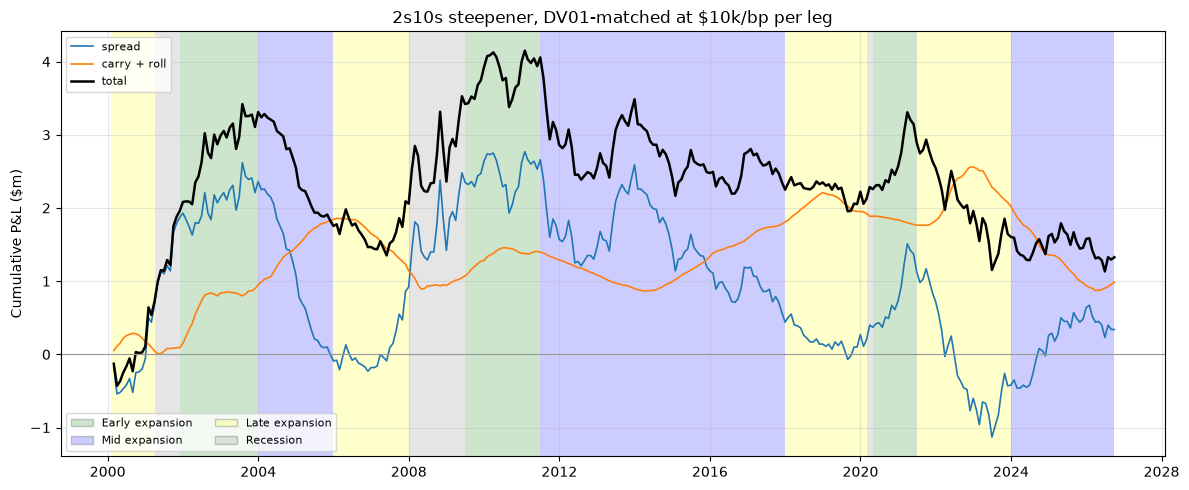

In [21]:
Path("data").mkdir(exist_ok=True)
fig, ax = plt.subplots(figsize=(12, 5))

shade_phases(ax, phase)

for label, col in [("spread", "spread_pnl"), ("carry + roll", "carry_roll"), ("total", "total_pnl")]:
    ax.plot(pnl.index, pnl[col].cumsum() / 1e6, label=label,
            color="black" if col == "total_pnl" else None,
            linewidth=1.8 if col == "total_pnl" else 1.2)

ax.axhline(0, color="0.6", linewidth=0.8)
ax.set_ylabel("Cumulative P&L ($m)")
ax.set_title("2s10s steepener, DV01-matched at $10k/bp per leg")
ax.grid(alpha=0.3)

series_legend = ax.legend(loc="upper left", fontsize=8)
ax.add_artist(series_legend)
ax.legend([plt.Rectangle((0, 0), 1, 1, linewidth=1, edgecolor="black", facecolor=c, alpha=0.20) for c in PHASE_COLORS.values()],
          list(PHASE_COLORS), loc="lower left", fontsize=8, ncol=2)

plt.tight_layout()
plt.show()

In [22]:
ANALYSIS = ["spread_pnl", "carry_roll", "total_pnl"]


def pnl_by(labels, order=None):
    table = pnl.groupby(labels, observed=False)[ANALYSIS].sum() / 1e6
    table["months"] = pnl.groupby(labels, observed=False).size()
    table["$k / month"] = table["total_pnl"] * 1000 / table["months"]
    return table if order is None else table.reindex(order)


recession = (phase == "Recession").map({False: "Expansion", True: "Recession"})
pnl_by(recession, ["Expansion", "Recession"]).round(2)

,spread_pnl,carry_roll,total_pnl,months,$k / month
Expansion,-2.45,1.05,-1.40,292,-4.79
Recession,2.79,-0.06,2.73,28,97.35


In [23]:
pnl_by(phase, PHASES).round(2)

,spread_pnl,carry_roll,total_pnl,months,$k / month
Early expansion,1.56,1.06,2.62,63,41.62
Mid expansion,-3.91,0.27,-3.64,135,-26.97
Late expansion,-0.10,-0.28,-0.38,94,-4.05
Recession,2.79,-0.06,2.73,28,97.35
